In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("output/customer_churn_cleaned.csv")

print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

Dataset Shape: (600, 14)

Columns:
['CustomerID', 'Age', 'Region', 'TenureMonths', 'SubscriptionType', 'MonthlyChargesINR', 'TotalChargesINR', 'ContractType', 'SupportTickets', 'LatePayments', 'PaymentMethod', 'AutoPay', 'Churn', 'MonthlyChargesOutlier']


,CustomerID,Age,Region,TenureMonths,SubscriptionType,MonthlyChargesINR,TotalChargesINR,ContractType,SupportTickets,LatePayments,PaymentMethod,AutoPay,Churn,MonthlyChargesOutlier
0,CUST-100001,20,Unknown,9,Pro,13097.76,NaN,Month-to-Month,1,2,Card,No,Yes,True
1,CUST-100002,55,Central,52,Pro,1101.18,57334.22,One Year,0,0,Card,Yes,No,False
2,CUST-100003,40,Central,67,Standard,692.66,44554.47,Month-to-Month,6,2,UPI,No,Yes,False
3,CUST-100004,53,South,48,Pro,1156.49,53956.12,One Year,2,2,Card,Yes,No,False
4,CUST-100005,21,West,24,Standard,754.16,18191.59,Month-to-Month,0,1,Card,Yes,No,False


In [3]:
# Count churned and retained customers
churn_counts = df["Churn"].value_counts()

total_customers = len(df)
churned_customers = churn_counts.get("Yes", 0)
retained_customers = churn_counts.get("No", 0)

# Calculate churn rate
churn_rate = (churned_customers / total_customers) * 100

# Calculate retention rate
retention_rate = (retained_customers / total_customers) * 100

print("Total Customers:", total_customers)
print("Churned Customers:", churned_customers)
print("Retained Customers:", retained_customers)
print("Churn Rate:", round(churn_rate, 2), "%")
print("Retention Rate:", round(retention_rate, 2), "%")

Total Customers: 600
Churned Customers: 247
Retained Customers: 353
Churn Rate: 41.17 %
Retention Rate: 58.83 %


In [4]:
# Calculate CLV proxy
avg_monthly_charges = df["MonthlyChargesINR"].mean()
avg_tenure = df["TenureMonths"].mean()

estimated_clv = avg_monthly_charges * avg_tenure

# Median-based estimate to reduce outlier influence
median_clv = (
    df["MonthlyChargesINR"].median()
    * df["TenureMonths"].median()
)

print("Average Monthly Charges: ₹", round(avg_monthly_charges, 2))
print("Average Customer Tenure:", round(avg_tenure, 2), "months")
print("Estimated CLV (Mean-based): ₹", round(estimated_clv, 2))
print("CLV Proxy (Median-based): ₹", round(median_clv, 2))

Average Monthly Charges: ₹ 869.03
Average Customer Tenure: 35.54 months
Estimated CLV (Mean-based): ₹ 30886.88
CLV Proxy (Median-based): ₹ 24687.57


In [5]:
# Select churned customers
churned_df = df[df["Churn"] == "Yes"].copy()

# Calculate MRR loss
mrr_loss = churned_df["MonthlyChargesINR"].sum()

# Calculate average monthly revenue per churned customer
avg_churned_charge = churned_df["MonthlyChargesINR"].mean()

print("Churned Customers:", len(churned_df))
print("Total MRR Loss: ₹", round(mrr_loss, 2))
print("Average Monthly Charge of Churned Customers: ₹",
      round(avg_churned_charge, 2))

Churned Customers: 247
Total MRR Loss: ₹ 240102.48
Average Monthly Charge of Churned Customers: ₹ 972.07


In [6]:
contract_churn = df.groupby("ContractType").agg(
    Total_Customers=("CustomerID", "count"),
    Churned_Customers=("Churn", lambda x: (x == "Yes").sum())
)

contract_churn["Churn_Rate"] = (
    contract_churn["Churned_Customers"]
    / contract_churn["Total_Customers"] * 100
).round(2)

print(contract_churn)

                Total_Customers  Churned_Customers  Churn_Rate
ContractType                                                  
Month-to-Month              316                189       59.81
One Year                    164                 33       20.12
Two Year                    120                 25       20.83


In [7]:
# Create tenure groups
df["TenureGroup"] = pd.cut(
    df["TenureMonths"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 Months", "13-24 Months",
            "25-48 Months", "49-72 Months"]
)

# Calculate churn by tenure
tenure_churn = df.groupby(
    "TenureGroup", observed=False
).agg(
    Total_Customers=("CustomerID", "count"),
    Churned_Customers=("Churn", lambda x: (x == "Yes").sum())
)

tenure_churn["Churn_Rate"] = (
    tenure_churn["Churned_Customers"]
    / tenure_churn["Total_Customers"] * 100
).round(2)

print(tenure_churn)

              Total_Customers  Churned_Customers  Churn_Rate
TenureGroup                                                 
0-12 Months               104                 56       53.85
13-24 Months              110                 50       45.45
25-48 Months              188                 72       38.30
49-72 Months              198                 69       34.85


In [8]:
payment_churn = df.groupby("PaymentMethod").agg(
    Total_Customers=("CustomerID", "count"),
    Churned_Customers=("Churn", lambda x: (x == "Yes").sum())
)

payment_churn["Churn_Rate"] = (
    payment_churn["Churned_Customers"]
    / payment_churn["Total_Customers"] * 100
).round(2)

print(payment_churn)

               Total_Customers  Churned_Customers  Churn_Rate
PaymentMethod                                                
Card                       157                 59       37.58
Net Banking                140                 52       37.14
UPI                        142                 64       45.07
Wallet                     161                 72       44.72


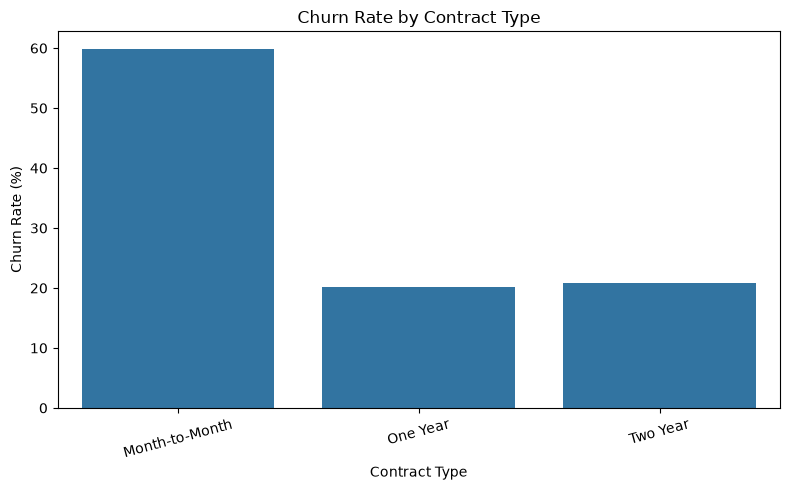

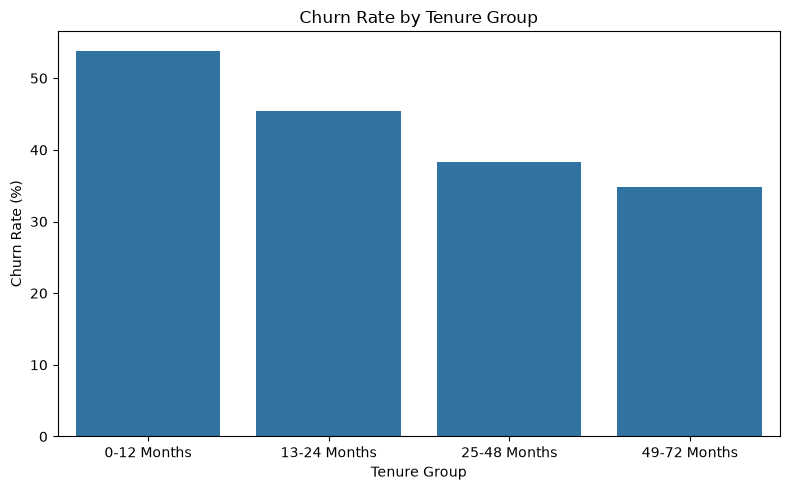

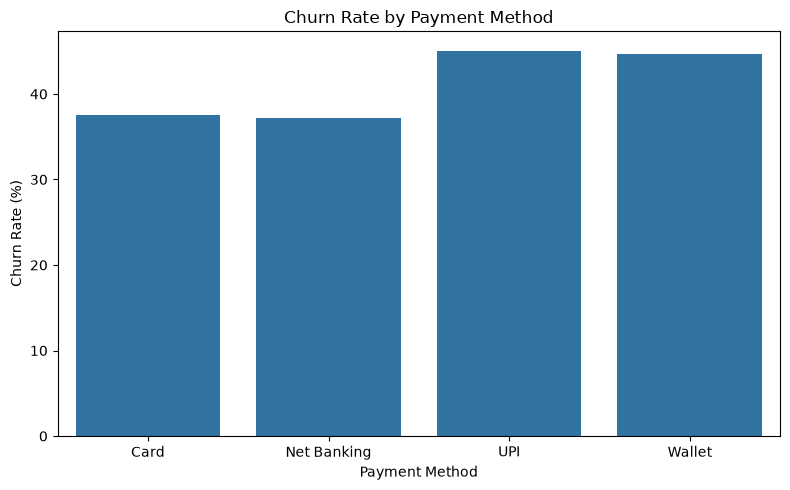

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Contract Type Churn Rate
plt.figure(figsize=(8, 5))
sns.barplot(
    x=contract_churn.index,
    y=contract_churn["Churn_Rate"]
)
plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


# 2. Tenure Group Churn Rate
plt.figure(figsize=(8, 5))
sns.barplot(
    x=tenure_churn.index.astype(str),
    y=tenure_churn["Churn_Rate"]
)
plt.title("Churn Rate by Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()


# 3. Payment Method Churn Rate
plt.figure(figsize=(8, 5))
sns.barplot(
    x=payment_churn.index,
    y=payment_churn["Churn_Rate"]
)
plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

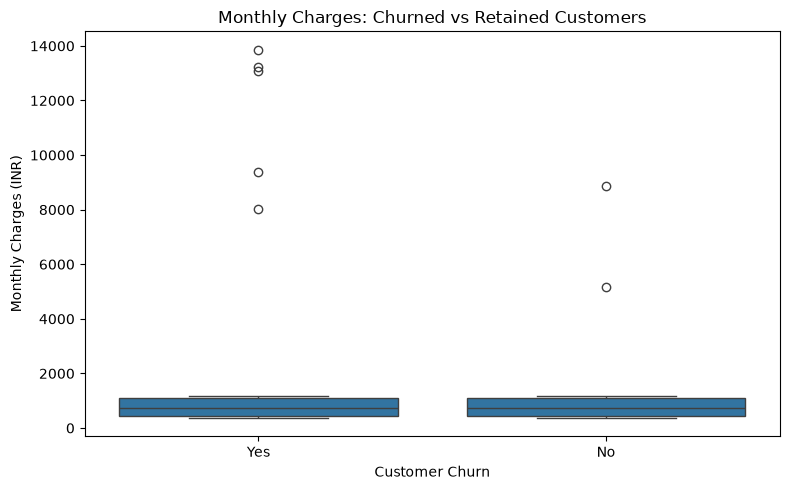

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyChargesINR"
)

plt.title("Monthly Charges: Churned vs Retained Customers")
plt.xlabel("Customer Churn")
plt.ylabel("Monthly Charges (INR)")
plt.tight_layout()
plt.show()

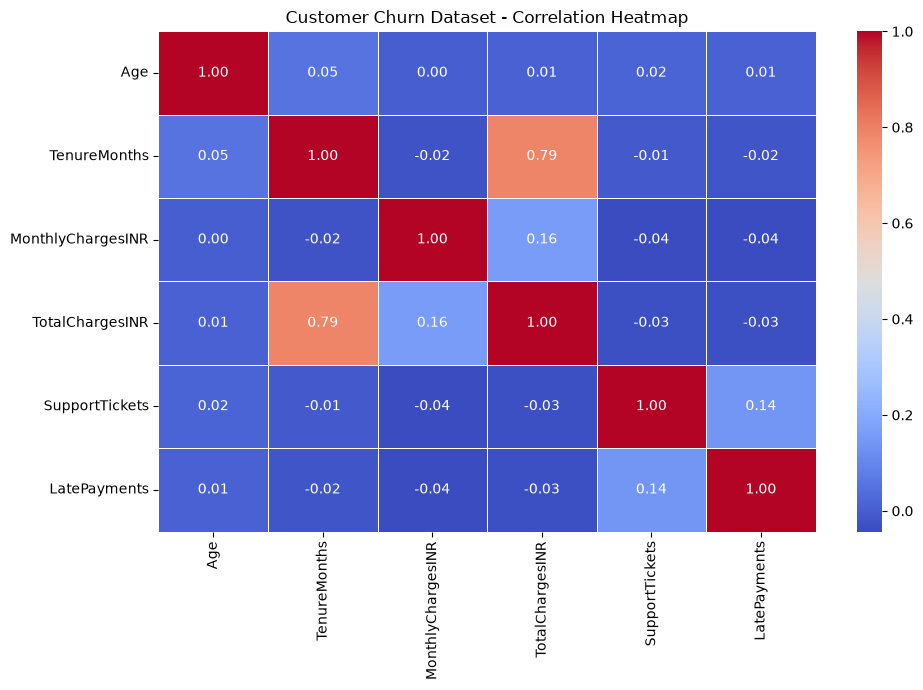

In [11]:
# Select numerical columns
numeric_df = df.select_dtypes(include=["number"])

# Calculate correlation
correlation = numeric_df.corr()

# Create heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Customer Churn Dataset - Correlation Heatmap")
plt.tight_layout()
plt.show()

In [12]:
# Churn rate by AutoPay
autopay_churn = df.groupby("AutoPay").agg(
    Total_Customers=("CustomerID", "count"),
    Churned_Customers=("Churn", lambda x: (x == "Yes").sum())
)

autopay_churn["Churn_Rate"] = (
    autopay_churn["Churned_Customers"]
    / autopay_churn["Total_Customers"] * 100
).round(2)

print("Churn by AutoPay:")
print(autopay_churn)


# Average support tickets and late payments
behavior_analysis = df.groupby("Churn").agg(
    Average_SupportTickets=("SupportTickets", "mean"),
    Average_LatePayments=("LatePayments", "mean")
).round(2)

print("\nBehavioral Comparison:")
print(behavior_analysis)

Churn by AutoPay:
         Total_Customers  Churned_Customers  Churn_Rate
AutoPay                                                
No                   250                103       41.20
Yes                  350                144       41.14

Behavioral Comparison:
       Average_SupportTickets  Average_LatePayments
Churn                                              
No                       1.51                  1.00
Yes                      2.12                  1.67


In [13]:
import os

os.makedirs("output", exist_ok=True)

contract_churn.to_csv(
    "output/contract_churn_analysis.csv"
)

tenure_churn.to_csv(
    "output/tenure_churn_analysis.csv"
)

payment_churn.to_csv(
    "output/payment_churn_analysis.csv"
)

autopay_churn.to_csv(
    "output/autopay_churn_analysis.csv"
)

behavior_analysis.to_csv(
    "output/behavior_analysis.csv"
)

print("All churn analysis tables exported successfully!")

All churn analysis tables exported successfully!


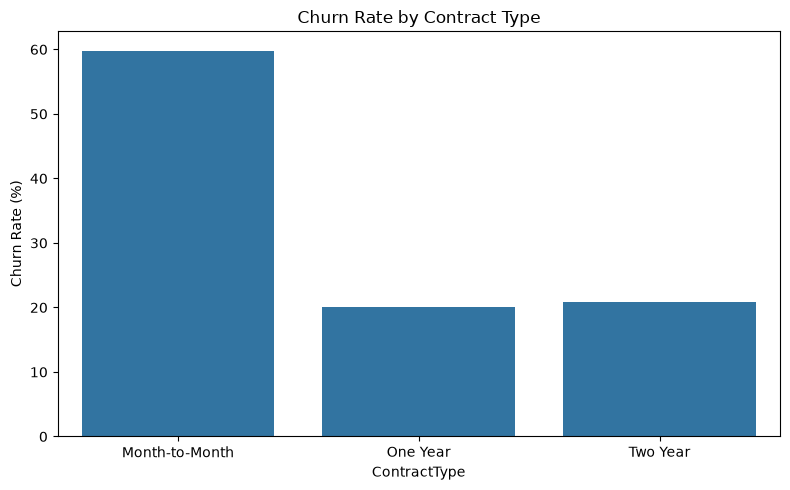

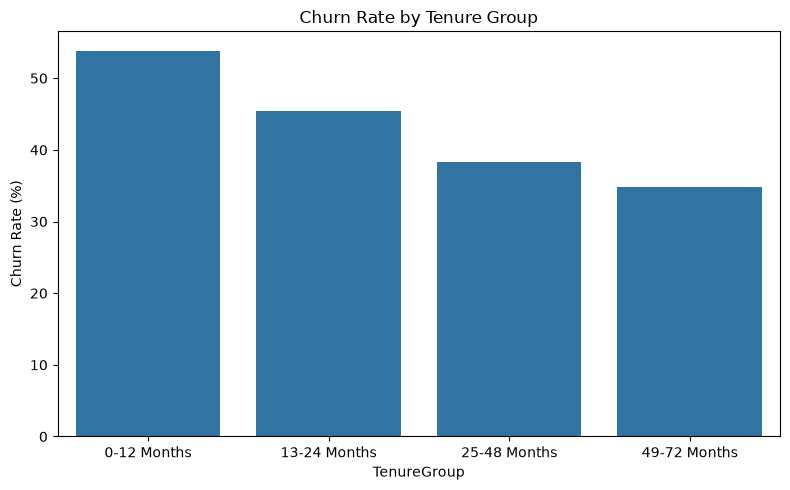

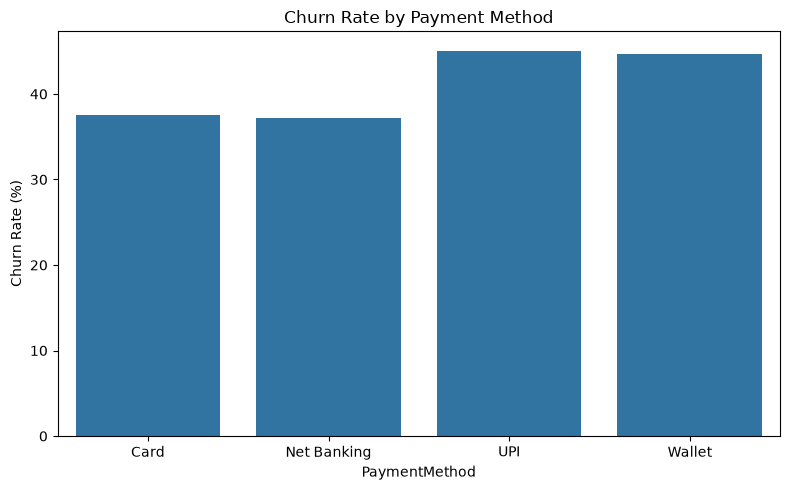

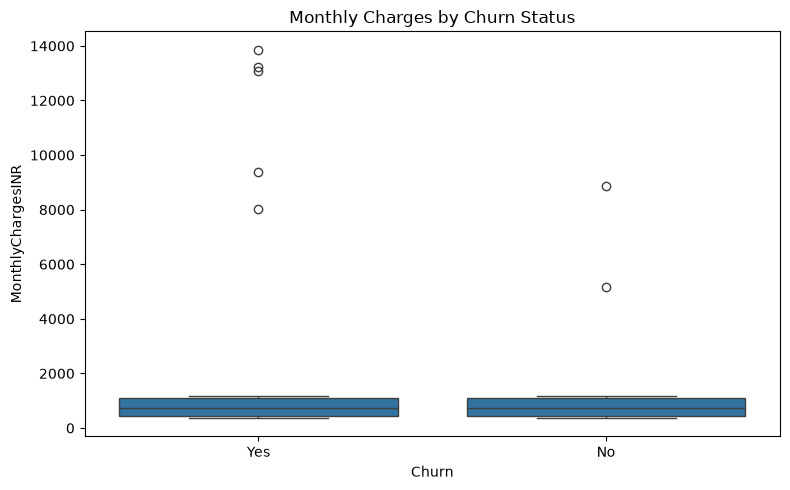

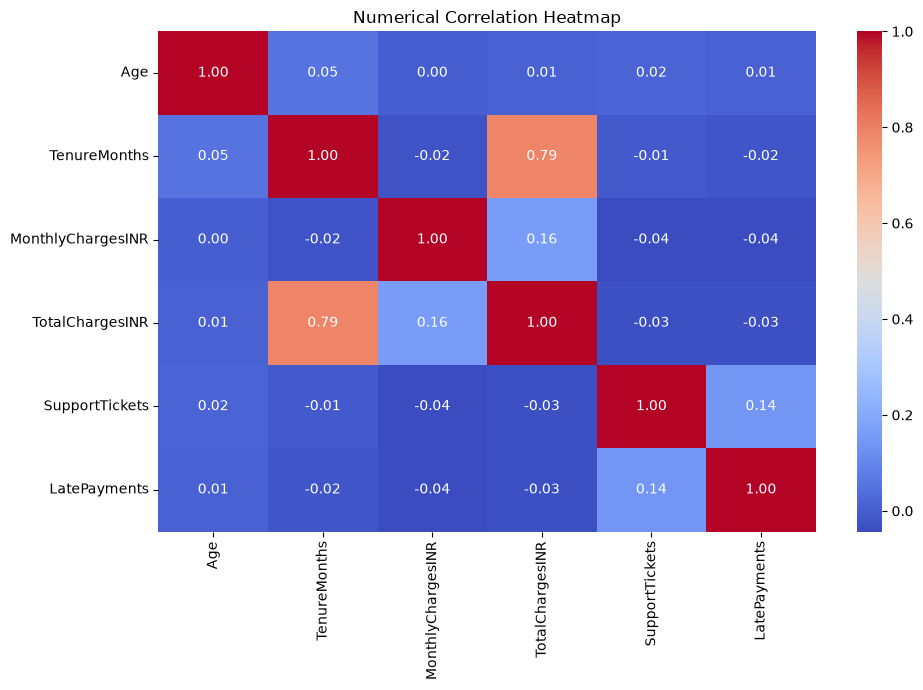

All 5 charts saved successfully!


In [14]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("output/charts", exist_ok=True)

# 1. Contract churn chart
plt.figure(figsize=(8, 5))
sns.barplot(x=contract_churn.index, y=contract_churn["Churn_Rate"])
plt.title("Churn Rate by Contract Type")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.savefig("output/charts/contract_churn.png", dpi=300)
plt.show()

# 2. Tenure churn chart
plt.figure(figsize=(8, 5))
sns.barplot(x=tenure_churn.index.astype(str), y=tenure_churn["Churn_Rate"])
plt.title("Churn Rate by Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.savefig("output/charts/tenure_churn.png", dpi=300)
plt.show()

# 3. Payment method chart
plt.figure(figsize=(8, 5))
sns.barplot(x=payment_churn.index, y=payment_churn["Churn_Rate"])
plt.title("Churn Rate by Payment Method")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.savefig("output/charts/payment_churn.png", dpi=300)
plt.show()

# 4. Boxplot
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Churn", y="MonthlyChargesINR")
plt.title("Monthly Charges by Churn Status")
plt.tight_layout()
plt.savefig("output/charts/monthly_charges_boxplot.png", dpi=300)
plt.show()

# 5. Heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(df.select_dtypes(include=["number"]).corr(),
            annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Numerical Correlation Heatmap")
plt.tight_layout()
plt.savefig("output/charts/correlation_heatmap.png", dpi=300)
plt.show()

print("All 5 charts saved successfully!")

In [16]:
%pip install reportlab

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\SHREE VATHY\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [17]:
import os
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import inch
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer,
    Table, TableStyle, Image, PageBreak
)

# Output path
pdf_path = "output/customer_churn_analytics_report.pdf"

styles = getSampleStyleSheet()

styles.add(ParagraphStyle(
    name="ReportTitle",
    parent=styles["Title"],
    fontSize=22,
    textColor=colors.HexColor("#17365D"),
    alignment=TA_CENTER,
    spaceAfter=15
))

styles.add(ParagraphStyle(
    name="SectionHeading",
    parent=styles["Heading2"],
    textColor=colors.HexColor("#1F4E79"),
    spaceBefore=12,
    spaceAfter=8
))

story = []

# Title
story.append(Paragraph(
    "CUSTOMER CHURN ANALYSIS",
    styles["ReportTitle"]
))
story.append(Paragraph(
    "Data Analytics Project | Workora Labs",
    styles["Heading2"]
))
story.append(Spacer(1, 15))

# Overview
story.append(Paragraph("1. Project Overview", styles["SectionHeading"]))
story.append(Paragraph(
    "This project analyzes a synthetic customer churn dataset to "
    "understand subscription cancellations, customer retention, "
    "revenue at risk and behavioral patterns.",
    styles["BodyText"]
))

story.append(Paragraph("2. Dataset Information", styles["SectionHeading"]))
dataset_data = [
    ["Metric", "Value"],
    ["Total Records", "600"],
    ["Total Columns", "14"],
    ["Churned Customers", "247"],
    ["Retained Customers", "353"]
]

table = Table(dataset_data, colWidths=[3*inch, 2*inch])
table.setStyle(TableStyle([
    ("BACKGROUND", (0,0), (-1,0), colors.HexColor("#17365D")),
    ("TEXTCOLOR", (0,0), (-1,0), colors.white),
    ("GRID", (0,0), (-1,-1), 0.5, colors.grey),
    ("PADDING", (0,0), (-1,-1), 7)
]))
story.append(table)

# Key metrics
story.append(Paragraph("3. Key Business Metrics", styles["SectionHeading"]))

metrics_data = [
    ["Metric", "Result"],
    ["Churn Rate", "41.17%"],
    ["Retention Rate", "58.83%"],
    ["Mean-based CLV Proxy", "INR 30,886.88"],
    ["Median-based CLV Proxy", "INR 24,687.57"],
    ["Estimated Monthly Revenue at Risk", "INR 240,102.48"]
]

table = Table(metrics_data, colWidths=[3.2*inch, 2.3*inch])
table.setStyle(TableStyle([
    ("BACKGROUND", (0,0), (-1,0), colors.HexColor("#17365D")),
    ("TEXTCOLOR", (0,0), (-1,0), colors.white),
    ("GRID", (0,0), (-1,-1), 0.5, colors.grey),
    ("PADDING", (0,0), (-1,-1), 7)
]))
story.append(table)

story.append(Paragraph(
    "CLV is estimated using average monthly charges multiplied by "
    "average tenure. It is a historical-value proxy, not a predictive "
    "future lifetime value. Revenue at risk is the sum of recorded "
    "monthly charges for churned customers.",
    styles["BodyText"]
))

# Analysis tables
def add_dataframe_table(title, dataframe):
    story.append(Paragraph(title, styles["SectionHeading"]))

    data = [["Category"] + list(dataframe.columns)]

    for index, row in dataframe.iterrows():
        data.append([str(index)] + [str(value) for value in row.values])

    t = Table(data, repeatRows=1)
    t.setStyle(TableStyle([
        ("BACKGROUND", (0,0), (-1,0), colors.HexColor("#17365D")),
        ("TEXTCOLOR", (0,0), (-1,0), colors.white),
        ("GRID", (0,0), (-1,-1), 0.5, colors.grey),
        ("FONTSIZE", (0,0), (-1,-1), 8),
        ("PADDING", (0,0), (-1,-1), 6)
    ]))
    story.append(t)

add_dataframe_table("4. Churn by Contract Type", contract_churn)
add_dataframe_table("5. Churn by Tenure Group", tenure_churn)
add_dataframe_table("6. Churn by Payment Method", payment_churn)
add_dataframe_table("7. Churn by AutoPay", autopay_churn)
add_dataframe_table("8. Behavioral Comparison", behavior_analysis)

# Charts
story.append(PageBreak())
story.append(Paragraph("9. Data Visualizations", styles["SectionHeading"]))

chart_files = [
    ("Churn Rate by Contract Type", "contract_churn.png"),
    ("Churn Rate by Tenure Group", "tenure_churn.png"),
    ("Churn Rate by Payment Method", "payment_churn.png"),
    ("Monthly Charges by Churn Status", "monthly_charges_boxplot.png"),
    ("Numerical Correlation Heatmap", "correlation_heatmap.png")
]

for title, filename in chart_files:
    path = os.path.join("output", "charts", filename)

    if os.path.exists(path):
        story.append(Paragraph(title, styles["Heading3"]))
        story.append(Image(path, width=6*inch, height=3.5*inch))
        story.append(Spacer(1, 12))

# Findings
story.append(PageBreak())
story.append(Paragraph("10. Key Findings", styles["SectionHeading"]))

findings = [
    "Month-to-Month contracts show the highest churn rate at 59.81%.",
    "Customers with 0-12 months of tenure show the highest churn rate at 53.85%.",
    "UPI users show a churn rate of 45.07%, followed by Wallet users at 44.72%.",
    "Churned customers average 2.12 support tickets compared with 1.51 for retained customers.",
    "Churned customers average 1.67 late payments compared with 1.00 for retained customers.",
    "AutoPay users and non-users show almost identical churn rates."
]

for item in findings:
    story.append(Paragraph("• " + item, styles["BodyText"]))
    story.append(Spacer(1, 6))

# Recommendations
story.append(Paragraph(
    "11. Business Recommendations",
    styles["SectionHeading"]
))

recommendations = [
    "Introduce suitable retention offers for Month-to-Month customers.",
    "Strengthen onboarding and engagement during the first 12 months.",
    "Investigate repeated support complaints and improve resolution time.",
    "Use payment reminders and investigate late-payment patterns.",
    "Review UPI and Wallet transaction experiences.",
    "Monitor customer churn indicators regularly."
]

for item in recommendations:
    story.append(Paragraph("• " + item, styles["BodyText"]))
    story.append(Spacer(1, 6))

# Limitations
story.append(Paragraph("12. Limitations", styles["SectionHeading"]))
story.append(Paragraph(
    "The dataset is synthetic. The analysis identifies associations, "
    "not proven causes of churn. CLV is a historical proxy, and monthly "
    "revenue at risk is an estimate based on recorded charges.",
    styles["BodyText"]
))

# Conclusion
story.append(Paragraph("13. Conclusion", styles["SectionHeading"]))
story.append(Paragraph(
    "The analysis identifies contract type, customer tenure, payment "
    "method, support tickets and late payments as useful areas for "
    "further customer-retention investigation.",
    styles["BodyText"]
))

story.append(Spacer(1, 25))
story.append(Paragraph(
    "<b>Prepared by: SHREE VATHY S</b><br/>"
    "B.E. Computer Science and Engineering<br/>"
    "Data Analytics Intern | Workora Labs",
    styles["BodyText"]
))

# Create PDF
doc = SimpleDocTemplate(
    pdf_path,
    pagesize=A4,
    rightMargin=40,
    leftMargin=40,
    topMargin=40,
    bottomMargin=40
)

doc.build(story)

print("PDF report generated successfully!")
print("Saved at:", os.path.abspath(pdf_path))

PDF report generated successfully!
Saved at: C:\Users\SHREE VATHY\OneDrive\Desktop\workora\output\customer_churn_analytics_report.pdf
